# FinSight — Model Experiments & Test Results

This notebook **presents and re-verifies** the centralised experiment (`experiments/run_experiments.py`). It does *not* contain separate model code: it imports the same registry (`experiments/model_registry.py`) and metric code (`experiments/evaluation.py`) the experiment uses.

**What you will see:** (1) the data split, (2) the six candidates and their grids, (3) every candidate re-fitted live with its chosen settings and scored, (4) cross-validation / validation search results, (5) how the winner is selected, (6) the comparison table and charts, (7) confusion matrices, (8) per-class reports, (9) the production model on the untouched test set.

**Method guard-rails:** TF-IDF is fitted *inside* each pipeline (never on the full data); hyper-parameters and the winner are chosen on **validation macro-F1** (CV on train as a supporting check); the **test set is used only for reporting, after selection**.

Set `RERUN = True` below to re-run the whole experiment (≈1 min). It overwrites `experiments/results/` and `models/`. Default is `False`: results are only *read*.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.image as mpimg, joblib
import config
from src import data as D
from experiments import evaluation as ev
from experiments.model_registry import CANDIDATES, build_pipeline, full_grid, TFIDF_FIXED
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
get_ipython().run_line_magic("matplotlib", "inline")   # evaluation.py selects the Agg backend for scripts; restore inline plots here

RERUN = False
if RERUN:
    from experiments import run_experiments; run_experiments.main()

R = config.RESULTS_DIR
saved = json.loads((R / "metrics.json").read_text(encoding="utf-8"))
comp = pd.read_csv(R / "comparison.csv")
print("Loaded saved results from", R)

Loaded saved results from D:\FinSight\experiments\results


## 1. Data and split
The cleaned dataset (4,836 rows) is split once, stratified, seed 42, into 70% train / 15% validation / 15% test. Every model sees identical indices.

In [2]:
df, tr, va, te = D.get_splits()
X, y = df["sentence"], df["label"]
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]
split = pd.DataFrame({name: {"rows": len(idx), **{c: f"{100*(y[idx]==i).mean():.1f}%" for i, c in enumerate(config.LABEL_NAMES)}}
                      for name, idx in [("train", tr), ("validation", va), ("test", te)]}).T
display(split)
print("Overlap between splits (must be 0):", len(set(tr)&set(va)), len(set(tr)&set(te)), len(set(va)&set(te)))

,rows,negative,neutral,positive
train,3384,12.5%,59.4%,28.2%
validation,726,12.5%,59.4%,28.1%
test,726,12.5%,59.4%,28.1%


Overlap between splits (must be 0): 0 0 0


## 2. Candidate models and tuning grids
All candidates share the same TF-IDF front end; `ngram_range` (unigrams vs unigrams+bigrams) is tuned for every real model.

In [3]:
print("Fixed TF-IDF settings:", {k: (getattr(v, "__name__", v)) for k, v in TFIDF_FIXED.items()}, "\n")
rows = []
for n, c in CANDIDATES.items():
    g = full_grid(n); size = int(np.prod([len(v) for v in g.values()])) if g else 1
    rows.append({"model": n, "description": c.description, "grid": {k: v for k, v in g.items()} or "none (baseline)", "grid_points": size})
display(pd.DataFrame(rows).set_index("model"))

Fixed TF-IDF settings: {'preprocessor': 'normalize_text', 'lowercase': False, 'token_pattern': '(?u)\\b\\w+\\b|[%$€£]', 'min_df': 2, 'sublinear_tf': True} 



,description,grid,grid_points
model,,,
DummyClassifier,Majority-class baseline (always predicts the most frequent class),none (baseline),1
MultinomialNB,Multinomial Naive Bayes on TF-IDF,"{'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__alpha': ['0.1', '0.3', '1.0']}",6
ComplementNB,Complement Naive Bayes (designed for imbalanced text),"{'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__alpha': ['0.1', '0.3', '1.0']}",6
LogisticRegression,Multinomial logistic regression (L2),"{'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__C': [1, 10, 100], 'clf__class...",12
LinearSVC,"Linear support vector classifier (one-vs-rest, L2)","{'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__C': ['0.1', 1, 10], 'clf__cla...",12
SGDClassifier,Linear model trained by SGD with log-loss,"{'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__alpha': ['0.00001', '0.0001',...",12


## 3. Live re-fit and scores for every candidate
Each candidate is re-fitted here **on the training split only** with the settings chosen by the experiment, then scored on the validation set (used for selection) and the test set (reporting only). The numbers are checked against the saved results.

In [4]:
rows, preds_val, preds_test = [], {}, {}
for name, r in saved["models"].items():
    params = {k: (tuple(v) if isinstance(v, list) else v) for k, v in r["best_params"].items()}
    model = build_pipeline(name).set_params(**params).fit(Xtr, ytr)
    pv, pt = model.predict(Xva), model.predict(Xte)
    mv, mt = ev.compute_metrics(yva, pv), ev.compute_metrics(yte, pt)
    preds_val[name], preds_test[name] = pv, pt
    # verification against the saved experiment output
    assert np.isclose(mv["macro_f1"], r["validation"]["macro_f1"]) and np.isclose(mt["accuracy"], r["test"]["accuracy"]), f"{name}: mismatch with saved results"
    rows.append({"model": name, "val_accuracy": mv["accuracy"], "val_macro_f1": mv["macro_f1"], "test_accuracy": mt["accuracy"],
                 "test_macro_precision": mt["macro_precision"], "test_macro_recall": mt["macro_recall"], "test_macro_f1": mt["macro_f1"], "test_weighted_f1": mt["weighted_f1"]})
live = pd.DataFrame(rows).set_index("model").sort_values("val_macro_f1", ascending=False)
display(live.round(4).style.format("{:.4f}").background_gradient(cmap="YlGn", axis=0))
print("All live scores match the saved experiment results (assertions passed).")
print(f"Majority-class baseline accuracy to beat: {live.loc['DummyClassifier','test_accuracy']:.3f}")

,val_accuracy,val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1
model,,,,,,,
LinearSVC,0.8044,0.7621,0.7741,0.7484,0.7197,0.7313,0.7694
SGDClassifier,0.7906,0.7465,0.7700,0.7366,0.7150,0.7246,0.7666
LogisticRegression,0.7893,0.7431,0.7727,0.7385,0.7327,0.7349,0.7707
ComplementNB,0.7507,0.6899,0.7287,0.6806,0.6789,0.6777,0.7250
MultinomialNB,0.7521,0.6828,0.7369,0.7181,0.6495,0.6734,0.7235
DummyClassifier,0.5937,0.2483,0.5937,0.1979,0.3333,0.2483,0.4423


All live scores match the saved experiment results (assertions passed).
Majority-class baseline accuracy to beat: 0.594


## 4. Hyper-parameter search results
Every grid point was scored with 5-fold CV on the training split and on the validation split. Below: the best 4 settings per model (ranked by validation macro-F1, then CV).

In [5]:
for name, r in saved["models"].items():
    s = pd.DataFrame(r["search"]); s["params"] = s["params"].map(lambda p: ", ".join(f"{k.split('__')[-1]}={v}" for k, v in p.items()) or "(none)")
    s = s.sort_values(["val_macro_f1", "cv_macro_f1_mean"], ascending=False).head(4)
    print(f"\n{name}  ({r['n_grid_points']} grid points)"); display(s.round(4).reset_index(drop=True))


DummyClassifier  (1 grid points)


,params,cv_macro_f1_mean,cv_macro_f1_std,val_macro_f1,val_accuracy
0,(none),0.2483,0.0001,0.2483,0.5937



MultinomialNB  (6 grid points)


,params,cv_macro_f1_mean,cv_macro_f1_std,val_macro_f1,val_accuracy
0,"alpha=0.1, ngram_range=[1, 2]",0.6596,0.0293,0.6828,0.7521
1,"alpha=0.1, ngram_range=[1, 1]",0.6382,0.0234,0.6475,0.7218
2,"alpha=0.3, ngram_range=[1, 2]",0.6115,0.0215,0.6429,0.7424
3,"alpha=0.3, ngram_range=[1, 1]",0.6144,0.0106,0.6074,0.7135



ComplementNB  (6 grid points)


,params,cv_macro_f1_mean,cv_macro_f1_std,val_macro_f1,val_accuracy
0,"alpha=0.3, ngram_range=[1, 2]",0.6852,0.0189,0.6899,0.7507
1,"alpha=0.1, ngram_range=[1, 2]",0.6859,0.0252,0.6889,0.7452
2,"alpha=1.0, ngram_range=[1, 2]",0.6575,0.0336,0.6844,0.7534
3,"alpha=1.0, ngram_range=[1, 1]",0.6563,0.0279,0.6581,0.7149


... (2 outputs left out)


LinearSVC  (12 grid points)


,params,cv_macro_f1_mean,cv_macro_f1_std,val_macro_f1,val_accuracy
0,"C=1, class_weight=balanced, ngram_range=[1, 2]",0.7199,0.0114,0.7621,0.8044
1,"C=10, class_weight=balanced, ngram_range=[1, 2]",0.7072,0.0139,0.7355,0.7810
2,"C=1, class_weight=balanced, ngram_range=[1, 1]",0.7026,0.0228,0.7313,0.7741
3,"C=10, class_weight=None, ngram_range=[1, 2]",0.7051,0.0164,0.7291,0.7782



SGDClassifier  (12 grid points)


,params,cv_macro_f1_mean,cv_macro_f1_std,val_macro_f1,val_accuracy
0,"alpha=1e-05, class_weight=balanced, ngram_range=[1, 2]",0.7093,0.0198,0.7465,0.7906
1,"alpha=0.0001, class_weight=balanced, ngram_range=[1, 2]",0.7127,0.0146,0.7318,0.7837
2,"alpha=1e-05, class_weight=None, ngram_range=[1, 2]",0.7122,0.0180,0.7297,0.7851
3,"alpha=0.0001, class_weight=balanced, ngram_range=[1, 1]",0.7127,0.0191,0.7276,0.7672


## 5. Winner selection
Rule: **highest validation macro-F1**; ties broken by CV macro-F1, then faster inference, then name. Test results play no part.

In [6]:
sel = pd.DataFrame({n: {"validation_macro_F1": saved["models"][n]["validation"]["macro_f1"], "cv_macro_F1": saved["models"][n]["cv_macro_f1_mean"],
                        "cv_std": saved["models"][n]["cv_macro_f1_std"], "inference_ms/sentence": saved["models"][n]["inference_ms_per_sentence"]} for n in saved["ranking_by_validation"]}).T
sel.index.name = "rank order"; display(sel.round(4))
print("WINNER:", saved["winner"])
top = saved["ranking_by_validation"][:3]
print("Margin: validation macro-F1 lead over #2 = %.4f, over #3 = %.4f; CV std of the top models is ~%.3f -> the top three are close." % (
    sel.iloc[0, 0] - sel.iloc[1, 0], sel.iloc[0, 0] - sel.iloc[2, 0], sel.iloc[:3]["cv_std"].mean()))

,validation_macro_F1,cv_macro_F1,cv_std,inference_ms/sentence
rank order,,,,
LinearSVC,0.7621,0.7199,0.0114,0.0343
SGDClassifier,0.7465,0.7093,0.0198,0.0348
LogisticRegression,0.7431,0.7169,0.0121,0.0337
ComplementNB,0.6899,0.6852,0.0189,0.0340
MultinomialNB,0.6828,0.6596,0.0293,0.0377
DummyClassifier,0.2483,0.2483,0.0001,0.0215


WINNER: LinearSVC
Margin: validation macro-F1 lead over #2 = 0.0156, over #3 = 0.0190; CV std of the top models is ~0.014 -> the top three are close.


## 6. Full comparison table and charts

,selected,cv_macro_f1_mean,val_macro_f1,val_accuracy,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1,train_time_s,inference_ms_per_sentence,n_features,n_parameters
model,,,,,,,,,,,,,
LinearSVC,True,0.7199,0.7621,0.8044,0.7741,0.7484,0.7197,0.7313,0.7694,0.1788,0.0343,11737,35214
SGDClassifier,False,0.7093,0.7465,0.7906,0.7700,0.7366,0.7150,0.7246,0.7666,0.1660,0.0348,11737,35214
LogisticRegression,False,0.7169,0.7431,0.7893,0.7727,0.7385,0.7327,0.7349,0.7707,0.4164,0.0337,11737,35214
ComplementNB,False,0.6852,0.6899,0.7507,0.7287,0.6806,0.6789,0.6777,0.7250,0.1508,0.0340,11737,35214
MultinomialNB,False,0.6596,0.6828,0.7521,0.7369,0.7181,0.6495,0.6734,0.7235,0.1664,0.0377,11737,35214
DummyClassifier,False,0.2483,0.2483,0.5937,0.5937,0.1979,0.3333,0.2483,0.4423,0.0740,0.0215,3908,0


Per-class TEST metrics (models trained on train only)


negative                 neutral                positive              
                   precision recall     f1 precision recall     f1 precision recall     f1
model                                                                                     
LinearSVC              0.713  0.681  0.697     0.800  0.875  0.836     0.732  0.603  0.661
SGDClassifier          0.698  0.659  0.678     0.810  0.863  0.836     0.702  0.623  0.660
LogisticRegression     0.699  0.714  0.707     0.819  0.852  0.835     0.697  0.632  0.663
ComplementNB           0.606  0.659  0.632     0.785  0.828  0.806     0.651  0.549  0.596
MultinomialNB          0.726  0.582  0.646     0.757  0.896  0.820     0.671  0.471  0.553
DummyClassifier        0.000  0.000  0.000     0.594  1.000  0.745     0.000  0.000  0.000

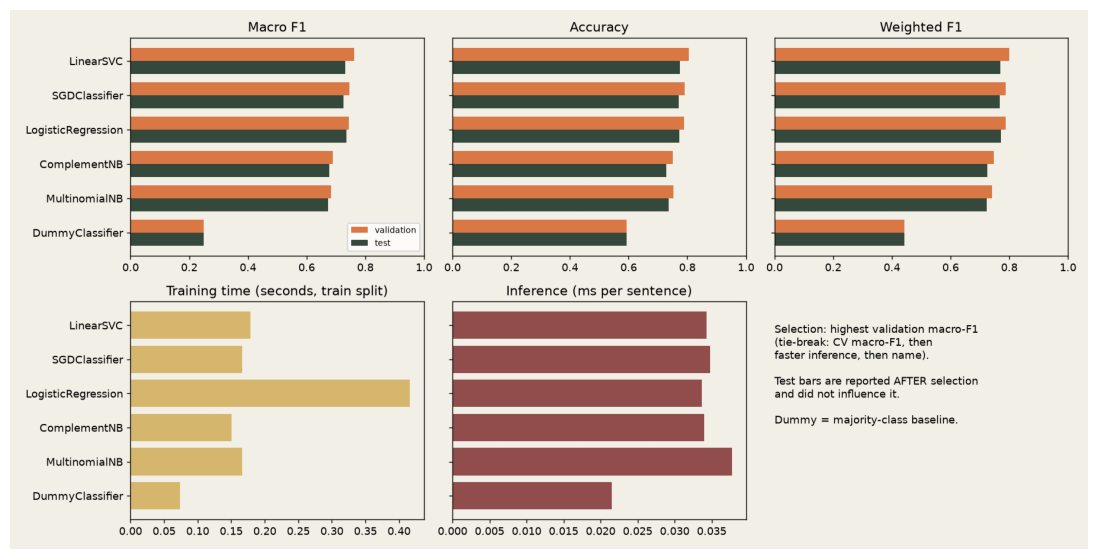

In [7]:
cols = ["model", "selected", "cv_macro_f1_mean", "val_macro_f1", "val_accuracy", "test_accuracy", "test_macro_precision", "test_macro_recall", "test_macro_f1", "test_weighted_f1",
        "train_time_s", "inference_ms_per_sentence", "n_features", "n_parameters"]
display(comp[cols].round(4).set_index("model"))
print("Per-class TEST metrics (models trained on train only)")
pc = comp.set_index("model")[[f"test_{c}_{k}" for c in config.LABEL_NAMES for k in ("precision", "recall", "f1")]]
pc.columns = pd.MultiIndex.from_product([config.LABEL_NAMES, ["precision", "recall", "f1"]]); display(pc.round(3))
fig = plt.figure(figsize=(14, 7)); plt.imshow(mpimg.imread(R / "comparison.png")); plt.axis("off"); plt.show()

## 7. Confusion matrices (test set, consistent label order: negative, neutral, positive)
Each cell shows the count and the percentage of the *true* class (i.e. recall along the diagonal). Models are trained on the training split only; the last panel is the production model (train+validation).

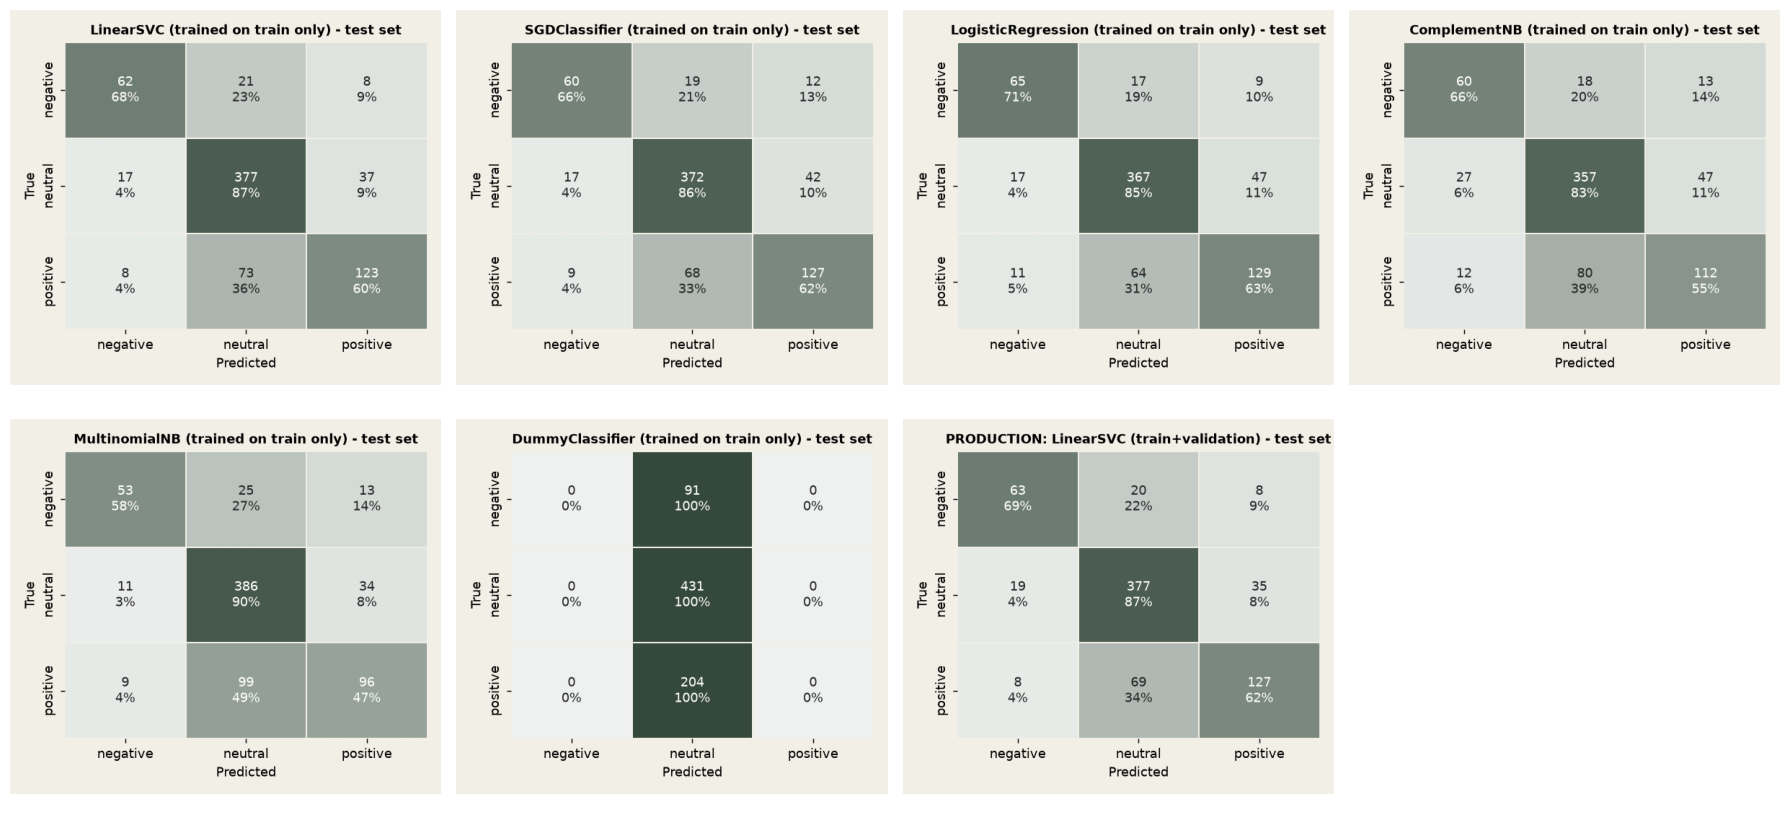

In [8]:
import matplotlib.image as mpimg
files = [f"{n}.png" for n in saved["ranking_by_validation"]] + [f"production_{saved['winner']}.png"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for a, f in zip(axes.ravel(), files): a.imshow(mpimg.imread(config.CONFUSION_DIR / f)); a.axis("off")
for a in axes.ravel()[len(files):]: a.axis("off")
plt.tight_layout(); plt.show()

## 8. Classification reports (test set)

In [9]:
for n in saved["ranking_by_validation"]:
    print("=" * 62, f"\n{n}   (accuracy {saved['models'][n]['test']['accuracy']:.4f})"); print(saved["models"][n]["classification_report_test"])

LinearSVC   (accuracy 0.7741)
              precision    recall  f1-score   support

    negative      0.713     0.681     0.697        91
     neutral      0.800     0.875     0.836       431
    positive      0.732     0.603     0.661       204

    accuracy                          0.774       726
   macro avg      0.748     0.720     0.731       726
weighted avg      0.770     0.774     0.769       726

SGDClassifier   (accuracy 0.7700)
              precision    recall  f1-score   support

    negative      0.698     0.659     0.678        91
     neutral      0.810     0.863     0.836       431
    positive      0.702     0.623     0.660       204

    accuracy                          0.770       726
   macro avg      0.737     0.715     0.725       726
weighted avg      0.766     0.770     0.767       726

LogisticRegression   (accuracy 0.7727)
              precision    recall  f1-score   support

    negative      0.699     0.714     0.707        91
     neutral      0.819   

## 9. Production model on the untouched test set
The winner was **refit on train+validation** and evaluated once on the test set. Here the saved production artifact (`models/best_model.joblib`) is loaded and re-scored to confirm it matches the recorded metadata.

In [10]:
model = joblib.load(config.MODELS_DIR / "best_model.joblib"); meta = json.loads((config.MODELS_DIR / "metadata.json").read_text(encoding="utf-8"))
pt = model.predict(Xte); m = ev.compute_metrics(yte, pt)
assert np.isclose(m["accuracy"], meta["final_test_metrics"]["accuracy"]) and np.isclose(m["macro_f1"], meta["final_test_metrics"]["macro_f1"])
print(f"Production model: {meta['model_name']}   |   tuned: {meta['model_config']['tuned_params']}")
print(f"Fitted on {meta['training_split']['production_model_fitted_on']}   |   trained {meta['training_date_utc']}")
print(f"\nTEST  accuracy = {m['accuracy']:.4f}   macro-F1 = {m['macro_f1']:.4f}   weighted-F1 = {m['weighted_f1']:.4f}   macro-P = {m['macro_precision']:.4f}   macro-R = {m['macro_recall']:.4f}")
print("(re-scored artifact matches metadata.json)\n"); print(ev.report_text(yte, pt))
cm = ev.conf_matrix(yte, pt); display(pd.DataFrame(cm, index=[f"true {c}" for c in config.LABEL_NAMES], columns=[f"pred {c}" for c in config.LABEL_NAMES]))
base = live.loc["DummyClassifier"]
print(f"Versus majority baseline: accuracy {base.test_accuracy:.3f} -> {m['accuracy']:.3f}; macro-F1 {base.test_macro_f1:.3f} -> {m['macro_f1']:.3f}")

Production model: LinearSVC   |   tuned: {'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': [1, 2]}
Fitted on train+validation (4110 rows); test set held out   |   trained 2026-11-07T21:08:58+00:00

TEST  accuracy = 0.7810   macro-F1 = 0.7386   weighted-F1 = 0.7771   macro-P = 0.7520   macro-R = 0.7299
(re-scored artifact matches metadata.json)

              precision    recall  f1-score   support

    negative      0.700     0.692     0.696        91
     neutral      0.809     0.875     0.841       431
    positive      0.747     0.623     0.679       204

    accuracy                          0.781       726
   macro avg      0.752     0.730     0.739       726
weighted avg      0.778     0.781     0.777       726



,pred negative,pred neutral,pred positive
true negative,63,20,8
true neutral,19,377,35
true positive,8,69,127


Versus majority baseline: accuracy 0.594 -> 0.781; macro-F1 0.248 -> 0.739


## 10. Reading the results honestly

- **Every real model clearly beats the baseline** (macro-F1 0.25 → ~0.67–0.74; accuracy 0.594 → ~0.73–0.78).
- **Linear models beat Naive Bayes** by roughly 5 macro-F1 points, on validation and on test.
- **The top three linear models are statistically close.** LinearSVC won on validation macro-F1, but its lead is small relative to CV standard deviations, and on the test set LogisticRegression scored marginally higher. Selection was *not* revised after seeing test results — that would be tuning on the test set. Differences of a point or less on 726 sentences should not be over-interpreted.
- **The winner's validation score (0.762) is optimistic** because hyper-parameters and the model were both chosen on validation; test scores are the honest estimate (≈0.73–0.74 macro-F1).
- **Weakest class: positive recall** (many positives predicted neutral), consistent with the EDA finding that the neutral/polar boundary is the hardest part of this dataset (contested annotations).
- **Timing** differences are tiny in absolute terms (all models predict in well under 0.1 ms per sentence); speed does not decide anything here.